<div style="background-color:#B5121B;color:#ffffff;padding:16px 22px;border-radius:6px;font-family:Arial, Helvetica, sans-serif;">
<div style="font-size:12px;letter-spacing:0.08em;text-transform:uppercase;opacity:0.85;">PHYS7101 &middot; Numerical Methods and Data Analysis</div>
<div style="font-size:21px;font-weight:700;margin-top:6px;line-height:1.3;">Week 3 — Interpolation and Extrapolation</div>
</div>

<div style="background-color:#38614A;color:#ffffff;padding:10px 16px;border-radius:4px;font-family:Arial, Helvetica, sans-serif;font-weight:700;margin-top:10px;">
Worked solutions: try each exercise yourself first, then compare.
</div>

#### Estimating between and beyond the data: filling gaps in the Mauna Loa CO₂ record, Runge's phenomenon, and what happens when you extrapolate.
***

## Where this fits

In Week 2 you fitted a model to the tide: a smooth function with a few parameters, chosen to describe *all* the data. Interpolation is different: it passes a curve *exactly through* known points to estimate values *between* them. Extrapolation uses either one to estimate values *beyond* the data, and that is where things go wrong.

The dataset is the Mauna Loa CO₂ record, monthly since 1958. Lecture 4 covers the methods. Today you will:

1. load and clean the record;
2. fill in deliberately removed months with linear, spline and polynomial interpolation;
3. see why more points can make a polynomial *worse* (Runge's phenomenon);
4. fit candidate models to 1958–1999 (the code is provided);
5. use them to predict 2000–2026, and check against what actually happened.

**Nothing here is assessed.** Write your predictions in your logbook before you run each comparison.

## How to use this notebook today

**Core (about 1¼ hours):** Sections 0, 1(a)–(b) and 2, then run Section 3 and do 4(a) and 4(c). Parts marked *Optional* can wait.

**Working on Exercise 1?** From this notebook you need the cubic spline and the leave-out check in Section 1. Do those, then use the rest of the lab for the exercise.

**Behind on earlier weeks?** Catch up first on what Exercise 1 builds on: `week1_euler_rk4_lab.ipynb` (Sections 1–3 and 5), `week2_root_finding.ipynb` (Sections 1, 2 and 5), `week2_fitting.ipynb` (Sections 2–4) and `week2_code_and_plots.ipynb` (Section 6). This notebook will still be here.

## <span style="color:#B5121B">0. Load and clean the data</span>

The file is NOAA's monthly record, unchanged. Open it in a text editor first (or look at it on GitHub): it starts with comment lines beginning `#`, then the columns:

| Column | Meaning |
|---|---|
| `year`, `month` | calendar month |
| `decimal date` | mid-month as a decimal year |
| `average` | monthly mean CO₂ (ppm, parts per million) |
| `deseasonalized` | the same with the average seasonal cycle removed |
| `ndays` | number of days with data |
| `sdev`, `unc` | standard deviation of the daily values, and uncertainty of the monthly mean (ppm) |

The header notes say that **missing values are marked with negative numbers**, and that missing months have already been filled by NOAA.

In [1]:
import os

# Data: read from a local datasets/ folder if you've cloned/downloaded the
# repository, otherwise straight from GitHub (e.g. in Colab). Same file either way.
DATA_URL = "https://raw.githubusercontent.com/MatSmithAstro/phys7101_2026_resources/main/workshops/week3/datasets/"

def data_path(filename):
    local = os.path.join("datasets", filename)
    return local if os.path.exists(local) else DATA_URL + filename

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

co2 = pd.read_csv(data_path("co2_mm_mlo.csv"), comment="#")   # comment="#" skips the header notes
co2.head()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99
3,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99
4,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99


822 months; 195 flagged, years 1958-1975
Flagged months after 1974:
     year  month  average
213  1975     12   330.77


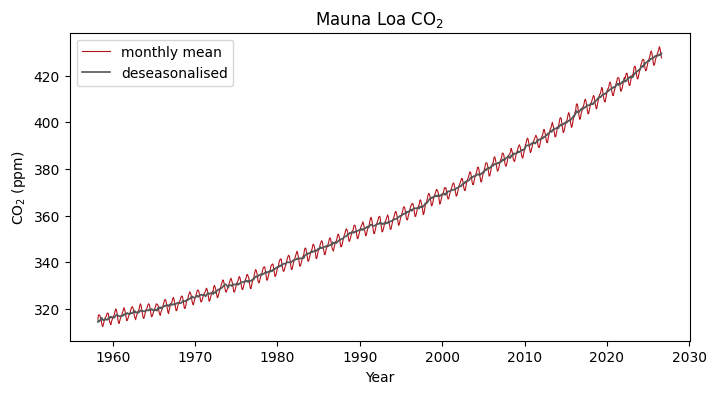

In [3]:
flagged = co2["ndays"] < 0
print(f"{len(co2)} months; {flagged.sum()} flagged, years {co2.loc[flagged, 'year'].min()}-{co2.loc[flagged, 'year'].max()}")
print("Flagged months after 1974:")
print(co2.loc[flagged & (co2["year"] > 1974), ["year", "month", "average"]])

for col in ["sdev", "unc"]:
    co2.loc[co2[col] < 0, col] = np.nan

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(co2["decimal date"], co2["average"], lw=0.8, color="#B5121B", label="monthly mean")
ax.plot(co2["decimal date"], co2["deseasonalized"], lw=1.2, color="#555656", label="deseasonalised")
ax.set_xlabel("Year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.set_title("Mauna Loa CO$_2$")
ax.legend()
plt.show()

<span style="color:#38614A">**Answer.**</span> 822 months, March 1958 to August 2026, with no gaps. 195 months are flagged: everything from the Scripps era (March 1958 to April 1974, for which NOAA has no daily statistics, so these months have no uncertainty), plus December 1975, a month NOAA filled by interpolation. So the record is already partly interpolated, which is worth knowing before using it.

In [4]:
# Used throughout: time and CO2 as NumPy arrays
t = co2["decimal date"].to_numpy()
y = co2["average"].to_numpy()

In your logbook: describe the two features of the curve in one line each. Roughly how big is the seasonal cycle (peak to trough, ppm)?

## <span style="color:#B5121B">1. Fill the gaps</span>

Take the four years 2018–2021 and **keep only every second month**. The months you remove are the test set: you know their true values, so you can measure how well each method recovers them. This is the check from Lecture 4: leave out points, interpolate from the rest, and compare.

The monthly means have uncertainties of 0.1–0.5 ppm, much smaller than the seasonal swing, so treating them as exact values is reasonable here. (Lecture 4: interpolate exact values; fit noisy ones. Extension B shows the difference.)

**(a)** Write your own `linear_interp(x_known, y_known, x)`: for each `x`, find the two known points either side and join them with a straight line. Check it against `np.interp`.

In [5]:
window = (t >= 2018) & (t < 2022)
t_win, y_win = t[window], y[window]

keep = np.arange(0, len(t_win), 2)            # every second month
t_known, y_known = t_win[keep], y_win[keep]

# test points: the removed months that lie inside the known range
inside = (t_win > t_known[0]) & (t_win < t_known[-1])
test = np.setdiff1d(np.where(inside)[0], keep)
t_test, y_test = t_win[test], y_win[test]
print(f"{len(t_known)} known points, {len(t_test)} test points")

24 known points, 23 test points


In [6]:
def linear_interp(x_known, y_known, x):
    """Piecewise-linear interpolation. x_known must be increasing.

    Returns an array of interpolated values at each x.
    """
    x = np.atleast_1d(x)
    i = np.searchsorted(x_known, x) - 1
    i = np.clip(i, 0, len(x_known) - 2)
    slope = (y_known[i + 1] - y_known[i]) / (x_known[i + 1] - x_known[i])
    return y_known[i] + slope * (x - x_known[i])

In [7]:
try:
    mine = linear_interp(t_known, y_known, t_test)
    print("max difference from np.interp:", np.max(np.abs(mine - np.interp(t_test, t_known, y_known))))
except NotImplementedError:
    print("Not implemented yet: complete the function above, then re-run this cell.")

max difference from np.interp: 0.0


**(b)** Now compare three methods on the test months. **Predict first** in your logbook: which will do best?

- linear: `np.interp`;
- cubic spline: `scipy.interpolate.CubicSpline`, piecewise cubics joined smoothly (continuous first and second derivatives);
- one polynomial through *all* the known points (degree $n - 1$): `np.polynomial.Polynomial.fit(t_known, y_known, deg=len(t_known) - 1)`.

For each, compute the rms error on the test months, and plot all three on a fine grid of times with the known and test points marked.

linear                   rms error = 0.519 ppm
cubic spline             rms error = 0.373 ppm
polynomial (degree 23)   rms error = 2.77e+03 ppm


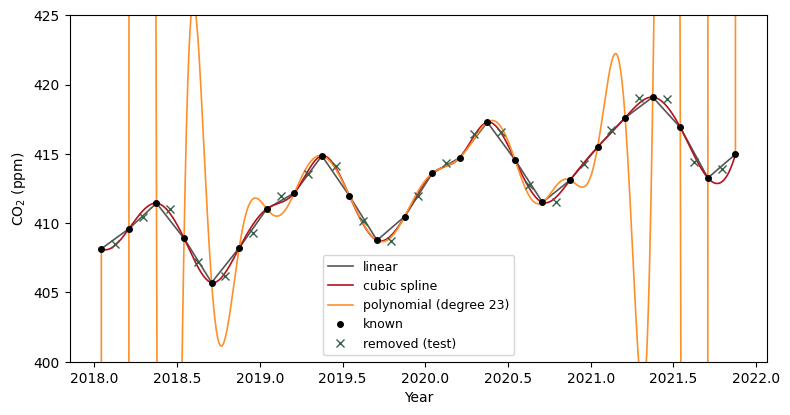

In [8]:
from scipy.interpolate import CubicSpline
from numpy.polynomial import Polynomial

methods = {
    "linear": lambda x: np.interp(x, t_known, y_known),
    "cubic spline": CubicSpline(t_known, y_known),
    f"polynomial (degree {len(t_known) - 1})": Polynomial.fit(t_known, y_known, deg=len(t_known) - 1),
}

t_fine = np.linspace(t_known[0], t_known[-1], 1000)
fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, f), colour in zip(methods.items(), ["#555656", "#B5121B", "#FD9029"]):
    rms = np.sqrt(np.mean((f(t_test) - y_test) ** 2))
    print(f"{name:24s} rms error = {rms:.3g} ppm")
    ax.plot(t_fine, f(t_fine), color=colour, lw=1.2, label=name)
ax.plot(t_known, y_known, "ko", ms=4, label="known")
ax.plot(t_test, y_test, "x", color="#38614A", ms=6, label="removed (test)")
ax.set_ylim(400, 425)
ax.set_xlabel("Year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend(fontsize=9)
plt.show()

<span style="color:#38614A">**Answer.**</span> Cubic spline 0.37 ppm, linear 0.52 ppm, the degree-23 polynomial about 3000 ppm. The spline wins because the seasonal cycle is curved and the spline follows curvature; linear interpolation cuts the corners at each peak and trough. The polynomial passes exactly through every known point but swings wildly between them near the ends of the window: by thousands of ppm. (`Polynomial.fit` also warns that the fit is poorly conditioned.) Passing through the data is no guarantee of being sensible between it.

**(c) Optional.** Repeat with only **every sixth month** kept (`keep = np.arange(0, len(t_win), 6)`). What happens to the linear and spline errors? Look at *which* months are left. In your logbook: why can no method recover the seasonal cycle now?

linear        rms error = 2.39 ppm
cubic spline  rms error = 2.43 ppm
months kept: [1 7 1 7 1 7 1 7]


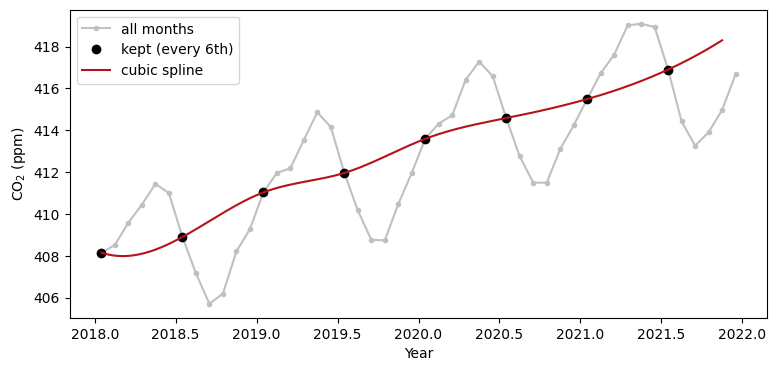

In [9]:
keep6 = np.arange(0, len(t_win), 6)
tk6, yk6 = t_win[keep6], y_win[keep6]
inside6 = (t_win > tk6[0]) & (t_win < tk6[-1])
test6 = np.setdiff1d(np.where(inside6)[0], keep6)
for name, f in [("linear", lambda x: np.interp(x, tk6, yk6)), ("cubic spline", CubicSpline(tk6, yk6))]:
    print(f"{name:13s} rms error = {np.sqrt(np.mean((f(t_win[test6]) - y_win[test6]) ** 2)):.2f} ppm")
print("months kept:", co2.loc[window, "month"].to_numpy()[keep6])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t_win, y_win, ".-", color="#BEC0C2", label="all months")
ax.plot(tk6, yk6, "ko", label="kept (every 6th)")
ax.plot(t_fine, CubicSpline(tk6, yk6)(t_fine), color="#B5121B", label="cubic spline")
ax.set_xlabel("Year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend()
plt.show()

<span style="color:#38614A">**Answer.**</span> Both errors jump to about 2.4 ppm. The kept months are always January and July, which sit at the same phase of the seasonal cycle each year, so the samples show only a gentle trend and the cycle is invisible. No interpolation method can recover a signal the samples don't contain. The sampling must be fine enough to resolve the variation you care about: here, at least a few points per cycle.

## <span style="color:#B5121B">2. Runge's phenomenon</span>

Section 1 showed a high-degree polynomial misbehaving near the ends. Here is the classic clean example. Interpolate

$$f(x) = \frac{1}{1 + 25x^2}, \qquad -1 \le x \le 1,$$

with a single polynomial through $n$ points. The **Lagrange form** of the interpolating polynomial is

$$p(x) = \sum_{j=0}^{n-1} y_j\, L_j(x), \qquad L_j(x) = \prod_{m \ne j} \frac{x - x_m}{x_j - x_m}.$$

Each $L_j$ is 1 at $x_j$ and 0 at every other node, so $p$ passes through every point.

**(a)** Write `lagrange(x_nodes, y_nodes, x)`.

In [10]:
def lagrange(x_nodes, y_nodes, x):
    """Evaluate the polynomial through (x_nodes, y_nodes) at x, using the Lagrange form."""
    x = np.asarray(x, dtype=float)
    total = np.zeros_like(x)
    for j in range(len(x_nodes)):
        L = np.ones_like(x)
        for m in range(len(x_nodes)):
            if m != j:
                L *= (x - x_nodes[m]) / (x_nodes[j] - x_nodes[m])
        total += y_nodes[j] * L
    return total

In [11]:
def runge(x):
    return 1 / (1 + 25 * x**2)

try:
    xn = np.array([-1.0, 0.0, 2.0])
    print(lagrange(xn, xn**2, np.array([0.5, 1.5])), "should be [0.25 2.25]")   # a parabola is reproduced exactly
except NotImplementedError:
    print("Not implemented yet: complete the function above, then re-run this cell.")

[0.25 2.25] should be [0.25 2.25]


**(b)** **Predict first:** with more equally spaced points, does the interpolant get better or worse?

For $n = 5, 9, 13, 17, 21$ equally spaced nodes, plot the interpolant and print the maximum error $\max|p(x) - f(x)|$ on a fine grid.

**(c)** Repeat with **Chebyshev nodes**, $x_k = \cos\left(\frac{(2k+1)\pi}{2n}\right)$, $k = 0, \dots, n-1$, which bunch up towards the ends. Then try a cubic spline through the equally spaced nodes. Make a table of the maximum error for all three.

 n   equal-spaced   Chebyshev    spline
 5     4.38e-01     4.02e-01    3.17e-01
 9     1.05e+00     1.71e-01    5.62e-02
13     3.66e+00     6.92e-02    6.91e-03
17     1.44e+01     3.26e-02    3.75e-03
21     5.98e+01     1.53e-02    3.18e-03


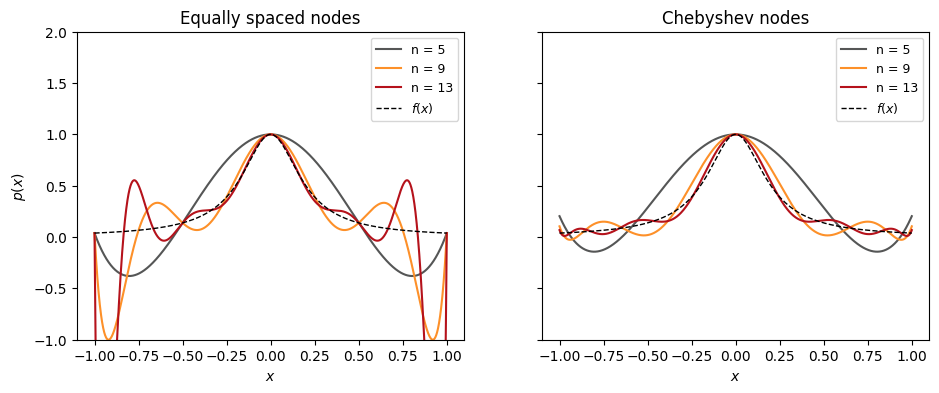

In [12]:
x_fine = np.linspace(-1, 1, 2001)
f_fine = runge(x_fine)

print(" n   equal-spaced   Chebyshev    spline")
for n in [5, 9, 13, 17, 21]:
    x_eq = np.linspace(-1, 1, n)
    x_ch = np.cos((2 * np.arange(n) + 1) * np.pi / (2 * n))
    e_eq = np.max(np.abs(lagrange(x_eq, runge(x_eq), x_fine) - f_fine))
    e_ch = np.max(np.abs(lagrange(x_ch, runge(x_ch), x_fine) - f_fine))
    e_sp = np.max(np.abs(CubicSpline(x_eq, runge(x_eq))(x_fine) - f_fine))
    print(f"{n:2d}   {e_eq:10.2e}   {e_ch:10.2e}   {e_sp:9.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for n, colour in [(5, "#555656"), (9, "#FD9029"), (13, "#B5121B")]:
    x_eq = np.linspace(-1, 1, n)
    x_ch = np.cos((2 * np.arange(n) + 1) * np.pi / (2 * n))
    axes[0].plot(x_fine, lagrange(x_eq, runge(x_eq), x_fine), color=colour, label=f"n = {n}")
    axes[1].plot(x_fine, lagrange(x_ch, runge(x_ch), x_fine), color=colour, label=f"n = {n}")
for ax, title in zip(axes, ["Equally spaced nodes", "Chebyshev nodes"]):
    ax.plot(x_fine, f_fine, "k--", lw=1, label="$f(x)$")
    ax.set_title(title)
    ax.set_xlabel("$x$")
    ax.set_ylim(-1, 2)
    ax.legend(fontsize=9)
axes[0].set_ylabel("$p(x)$")
plt.show()

<span style="color:#38614A">**Answer.**</span> With equally spaced nodes the maximum error *grows*: 0.44, 1.05, 3.7, 14, 60 for $n$ = 5 to 21. The interpolant fits well in the middle and oscillates ever more wildly near $x = \pm 1$. Chebyshev nodes shrink the error steadily (0.40 down to 0.015), and the spline does better still (down to 0.003). Two lessons: a single high-degree polynomial through equally spaced data is a bad idea; and if you need polynomials, either choose where the nodes go (Chebyshev) or use low-degree pieces (splines).

In your logbook: was your prediction right? Which method would you use to interpolate measured data, where you can't choose the nodes?

## <span style="color:#B5121B">3. Candidate models for the CO₂ record</span>

Interpolation can't take you beyond the data. For that you need a model. Here we fit candidate models to **1958–1999 only** (the *training* data), so that Section 4 can test them against 2000–2026.

Each model is a polynomial trend plus an annual cycle and its first harmonic:

$$y(t) = \sum_{k=0}^{d} c_k (t - 1980)^k + \sum_{h=1}^{2} \left[a_h \cos(2\pi h t) + b_h \sin(2\pi h t)\right].$$

It is linear in the parameters, so this is the design-matrix least-squares fit from Week 2 (`week2_fitting.ipynb`, Section 1). Centring on 1980 keeps the columns from becoming enormous ($2000^5$ is about $3\times10^{16}$).

**The code is provided**, because the fitting is Week 2 material: run the next three cells, and look at the rms residuals and the residual plots.

In [13]:
def design_matrix(t, degree, n_harmonics=2):
    """Columns: (t-1980)^0 ... (t-1980)^degree, then cos and sin of 2*pi*h*t for h = 1..n_harmonics."""
    columns = [(t - 1980) ** k for k in range(degree + 1)]
    for h in range(1, n_harmonics + 1):
        columns += [np.cos(2 * np.pi * h * t), np.sin(2 * np.pi * h * t)]
    return np.column_stack(columns)

In [14]:
try:
    print(design_matrix(np.array([1980.0, 1981.5]), degree=2).round(3))
except NotImplementedError:
    print("Not implemented yet: complete the function above, then re-run this cell.")

[[ 1.    0.    0.    1.    0.    1.    0.  ]
 [ 1.    1.5   2.25 -1.    0.    1.   -0.  ]]


The cell below fits degrees $d = 1, 2, 3, 5$ to the training data (`np.linalg.lstsq(A, y, rcond=None)`), prints the rms of the residuals and plots them against time. In your logbook: which degree would you choose, on this evidence alone?

(The SIO-era months have no uncertainty, so this is an unweighted fit: rms residual plays the role χ² did in Week 2.)

degree 1: rms residual = 1.808 ppm
degree 2: rms residual = 0.806 ppm
degree 3: rms residual = 0.611 ppm
degree 5: rms residual = 0.528 ppm


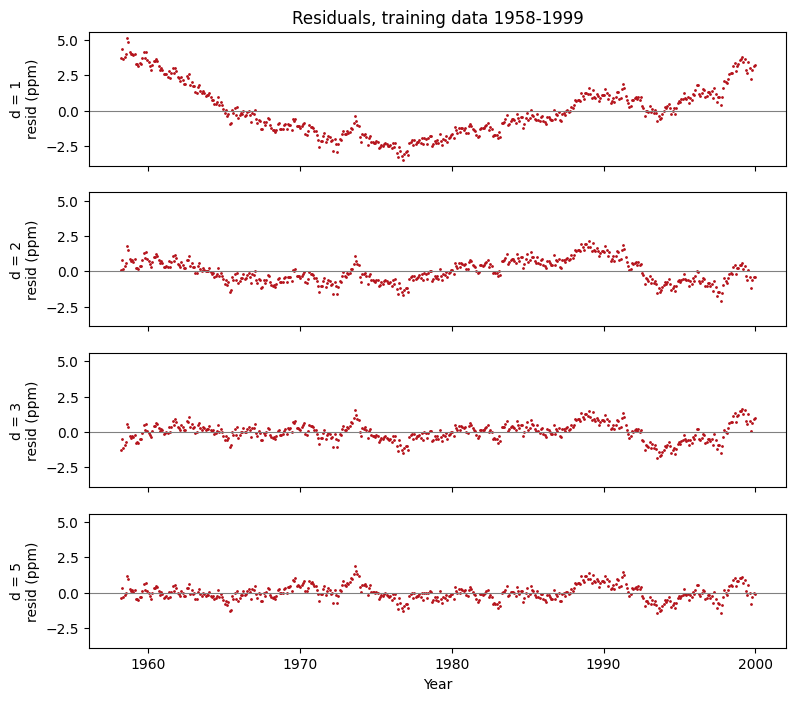

In [15]:
train = t < 2000
degrees = [1, 2, 3, 5]
params = {}

fig, axes = plt.subplots(len(degrees), 1, figsize=(9, 8), sharex=True, sharey=True)
for d, ax in zip(degrees, axes):
    A = design_matrix(t[train], d)
    theta, *_ = np.linalg.lstsq(A, y[train], rcond=None)
    params[d] = theta
    resid = y[train] - A @ theta
    print(f"degree {d}: rms residual = {np.sqrt(np.mean(resid**2)):.3f} ppm")
    ax.plot(t[train], resid, ".", ms=2, color="#B5121B")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_ylabel(f"d = {d}\nresid (ppm)")
axes[-1].set_xlabel("Year")
axes[0].set_title("Residuals, training data 1958-1999")
plt.show()

<span style="color:#38614A">**Answer.**</span> rms residuals: 1.81 (linear), 0.81 (quadratic), 0.61 (cubic), 0.53 ppm (quintic). The linear model's residuals form a clear U: the growth is accelerating. The quadratic removes most of that; the cubic and quintic remove a little more of the slow wobble. On the training data alone, every extra degree looks like an improvement.

**Optional aside.** Every extra parameter lowers the residuals a little, whether or not it describes anything real. A common way to penalise extra parameters is the *Bayesian information criterion*, $\text{BIC} = \chi^2 + k\ln n$ for $k$ parameters and $n$ points. Lower is better. With an assumed $\sigma = 0.3$ ppm, compute BIC for each degree. Does it stop the quintic winning? (Model comparison returns properly in Week 9.)

In [16]:
sigma, n = 0.3, train.sum()
for d in degrees:
    A = design_matrix(t[train], d)
    chi2_val = np.sum(((y[train] - A @ params[d]) / sigma) ** 2)
    print(f"degree {d}: k = {A.shape[1]:2d}, BIC = {chi2_val + A.shape[1] * np.log(n):8.0f}")

degree 1: k =  6, BIC =    18266
degree 2: k =  7, BIC =     3667
degree 3: k =  8, BIC =     2134
degree 5: k = 10, BIC =     1618


<span style="color:#38614A">**Answer.**</span> BIC still prefers the quintic (about 1600, against 3700 for the quadratic): the residuals fall by more than the penalty. In-sample criteria can't tell you how a model behaves *outside* the data. That's what Section 4 tests.

## <span style="color:#B5121B">4. Extrapolate: predict 2000–2026</span>

**Predict first**, in your logbook: which of the four models will best predict the CO₂ level in 2026? Write down a number for each if you can.

**(a)** Evaluate each fitted model from 1958 to 2026. Plot the predictions with the full record, marking where the training data ends. Print each model's prediction for the last month in the file, and its rms error over 2000–2026.

degree 1: 2026.62 prediction =  399.9 ppm (true 427.6); rms 2000-2026 =   15.7 ppm
degree 2: 2026.62 prediction =  426.1 ppm (true 427.6); rms 2000-2026 =    1.1 ppm
degree 3: 2026.62 prediction =  390.0 ppm (true 427.6); rms 2000-2026 =   18.2 ppm
degree 5: 2026.62 prediction =  783.7 ppm (true 427.6); rms 2000-2026 =  133.7 ppm


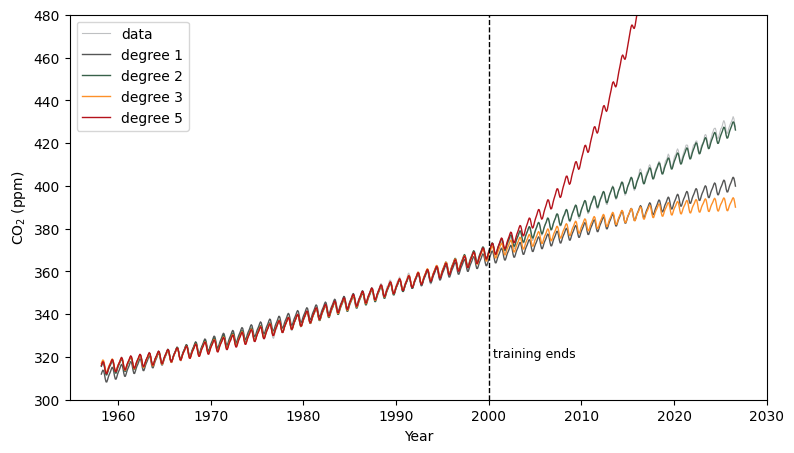

In [17]:
future = ~train
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(t, y, color="#BEC0C2", lw=0.8, label="data")
for d, colour in zip(degrees, ["#555656", "#38614A", "#FD9029", "#B5121B"]):
    pred = design_matrix(t, d) @ params[d]
    rms = np.sqrt(np.mean((pred[future] - y[future]) ** 2))
    print(f"degree {d}: {t[-1]:.2f} prediction = {pred[-1]:6.1f} ppm (true {y[-1]:.1f}); rms 2000-2026 = {rms:6.1f} ppm")
    ax.plot(t, pred, color=colour, lw=1, label=f"degree {d}")
ax.axvline(2000, color="k", ls="--", lw=1)
ax.text(2000.5, 320, "training ends", fontsize=9)
ax.set_ylim(300, 480)
ax.set_xlabel("Year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.legend()
plt.show()

<span style="color:#38614A">**Answer.**</span> For August 2026 (true 427.6 ppm): linear 400, quadratic 426, cubic 390, quintic 784 ppm. Over 2000–2026 the rms errors are 16, 1.1, 18 and 134 ppm. The quadratic, which looked only middling in Section 3, is by far the best predictor; the quintic, which "won" in-sample (including on BIC), is the worst by a factor of 100. The extra freedom fitted wiggles in 1958–1999 that the polynomial then amplifies outside the data, the same mechanism as Runge's phenomenon.

**(b) Optional.** Is the quadratic *always* the right choice? Move the end of the training data to **1990** and repeat (a). Which model wins now?

In [18]:
train90 = t < 1990
for d in degrees:
    th, *_ = np.linalg.lstsq(design_matrix(t[train90], d), y[train90], rcond=None)
    pred = design_matrix(t, d) @ th
    rms = np.sqrt(np.mean((pred[~train90] - y[~train90]) ** 2))
    print(f"degree {d}: {t[-1]:.2f} prediction = {pred[-1]:6.1f} ppm; rms 1990-2026 = {rms:6.1f} ppm")

degree 1: 2026.62 prediction =  394.4 ppm; rms 1990-2026 =   17.0 ppm
degree 2: 2026.62 prediction =  448.7 ppm; rms 1990-2026 =   11.6 ppm
degree 3: 2026.62 prediction =  435.3 ppm; rms 1990-2026 =    6.0 ppm
degree 5: 2026.62 prediction =  843.1 ppm; rms 1990-2026 =  146.2 ppm


<span style="color:#38614A">**Answer.**</span> With training ending in 1990, the cubic predicts best (rms 6 ppm, 435 ppm in 2026) and the quadratic overshoots (449 ppm). The "best" extrapolating model depends on an arbitrary choice of where the data stops. That instability is the real warning: a good fit to the past doesn't tell you which model to trust for the future.

**(c)** Two traps when extrapolating with interpolation tools. Run the cell below. What does `np.interp` return outside the data, and does it warn you? What does a cubic spline built on 1958–1999 predict for 2010?

In [19]:
print("np.interp at 2030:", np.interp(2030, t, y))
print("np.interp at 1900:", np.interp(1900, t, y))
spline_train = CubicSpline(t[train], y[train])
print(f"cubic spline (1958-1999) at 2010: {spline_train(2010):.0f} ppm")

np.interp at 2030: 427.55
np.interp at 1900: 315.71
cubic spline (1958-1999) at 2010: -57138 ppm


<span style="color:#38614A">**Answer.**</span> `np.interp` silently returns the end value (427.6 ppm in 2030, 315.7 ppm in 1900): no warning, and the answer looks plausible. The spline extrapolates its last cubic piece, which is fitted to the seasonal wiggle of late 1999, and predicts about −57,000 ppm for 2010. Interpolation tools are for *between* the data: check what yours does at the edges.

**(d) Optional.** Use each of the four models (trained to 1999) to predict CO₂ in **2050**. How large is the spread? In your logbook: if someone gave you only one of these numbers, what would you want to know before believing it?

In [20]:
for d in degrees:
    print(f"degree {d}: 2050 prediction = {(design_matrix(np.array([2050.5]), d) @ params[d])[0]:7.0f} ppm")

degree 1: 2050 prediction =     435 ppm
degree 2: 2050 prediction =     496 ppm
degree 3: 2050 prediction =     365 ppm
degree 5: 2050 prediction =    3779 ppm


<span style="color:#38614A">**Answer.**</span> The four predictions run from 365 ppm (cubic, which has turned over and predicts a *fall*) to about 3800 ppm (quintic); even the two simplest models differ by 60 ppm. Before believing any single extrapolation you'd want to know: what model was used and why; how sensitive the answer is to the model and the training window; and whether there's a *physical* reason to expect the trend to continue in that form. The data alone can't decide.

## <span style="color:#FD9029">Extension A (optional): a physically motivated model</span>

Polynomials have no physical meaning. A simple physical picture: CO₂ is a pre-industrial baseline of about 280 ppm plus an excess that grows exponentially,

$$y(t) = 280 + A\,e^{(t - 1990)/\tau} + \text{annual cycle}.$$

It's nonlinear in $\tau$, so use `curve_fit` (Week 2, `week2_fitting.ipynb` Section 4). Fit 1958–1999, report $A$ and $\tau$, and predict 2026. Does building in physics help the extrapolation? What might the model be missing?

In [21]:
from scipy.optimize import curve_fit

def co2_exp(t, A, tau, a1, b1, a2, b2):
    """Baseline 280 ppm + exponential excess + annual cycle and first harmonic."""
    return (280 + A * np.exp((t - 1990) / tau)
            + a1 * np.cos(2 * np.pi * t) + b1 * np.sin(2 * np.pi * t)
            + a2 * np.cos(4 * np.pi * t) + b2 * np.sin(4 * np.pi * t))

p, cov = curve_fit(co2_exp, t[train], y[train], p0=[70, 50, 0, 0, 0, 0])
pred = co2_exp(t, *p)
print(f"A = {p[0]:.1f} ppm, tau = {p[1]:.1f} yr")
print(f"rms residual 1958-1999 = {np.sqrt(np.mean((y[train] - pred[train])**2)):.2f} ppm")
print(f"{t[-1]:.2f} prediction = {pred[-1]:.1f} ppm (true {y[-1]:.1f})")

A = 72.1 ppm, tau = 43.6 yr
rms residual 1958-1999 = 0.98 ppm
2026.62 prediction = 445.5 ppm (true 427.6)


<span style="color:#38614A">**Answer.**</span> $A \approx 72$ ppm and $\tau \approx 44$ yr. It predicts about 446 ppm for 2026, 18 ppm too high: worse than the quadratic, better than the cubic. The excess has grown more slowly than the 1958–1999 exponential implied. The model assumes the growth *rate* keeps increasing in proportion to the excess, but emissions (the actual driver) have not grown exponentially since 2000, and the ocean and land take up part of each year's emissions. A physical model only helps if its physics is right for the period you extrapolate into.

## <span style="color:#FD9029">Extension B (optional): interpolation vs smoothing</span>

Interpolation goes exactly through every point, noise included. For noisy data that is usually not what you want.

Take $f(x) = \sin(2\pi x)$ at 60 equally spaced points on $[0, 2]$ and add Gaussian noise with $\sigma = 0.2$ (`np.random.default_rng(2)`). Compare:

- a `CubicSpline` through the noisy points;
- `scipy.interpolate.UnivariateSpline(x, y_noisy, s=...)`, a *smoothing* spline, which may miss the points by a total squared distance `s`. Start with $s = n\sigma^2$.

Measure each one's rms difference from the true $f(x)$ on a fine grid. Then scan `s` from $0.1\,n\sigma^2$ to $10\,n\sigma^2$ and plot the rms error against `s`. What happens at each end?

interpolating spline: rms from truth = 0.188
smoothing spline:     rms from truth = 0.048


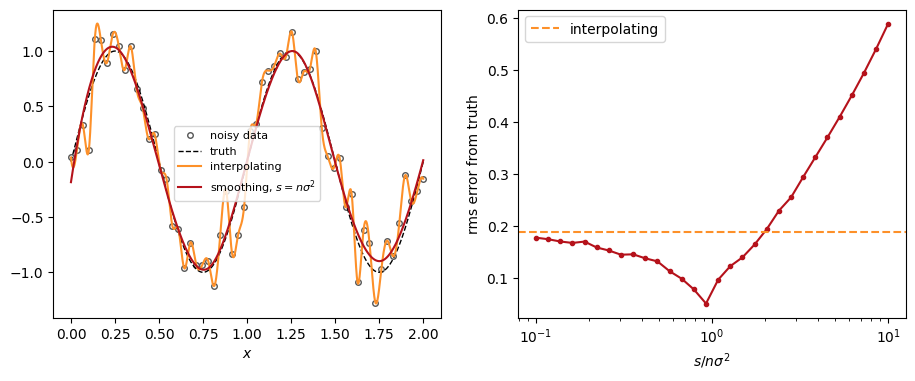

In [22]:
from scipy.interpolate import UnivariateSpline

sigma, n = 0.2, 60
x = np.linspace(0, 2, n)
f_true = lambda x: np.sin(2 * np.pi * x)
rng = np.random.default_rng(2)
y_noisy = f_true(x) + rng.normal(0, sigma, n)
x_f = np.linspace(0, 2, 2000)
rms = lambda g: np.sqrt(np.mean((g(x_f) - f_true(x_f)) ** 2))

interp = CubicSpline(x, y_noisy)
smooth = UnivariateSpline(x, y_noisy, s=n * sigma**2)
print(f"interpolating spline: rms from truth = {rms(interp):.3f}")
print(f"smoothing spline:     rms from truth = {rms(smooth):.3f}")

factors = np.logspace(-1, 1, 30)
errors = [rms(UnivariateSpline(x, y_noisy, s=k * n * sigma**2)) for k in factors]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x, y_noisy, "o", color="#555656", mfc="none", ms=4, label="noisy data")
axes[0].plot(x_f, f_true(x_f), "k--", lw=1, label="truth")
axes[0].plot(x_f, interp(x_f), color="#FD9029", label="interpolating")
axes[0].plot(x_f, smooth(x_f), color="#B5121B", label="smoothing, $s = n\sigma^2$")
axes[0].legend(fontsize=8)
axes[0].set_xlabel("$x$")
axes[1].semilogx(factors, errors, "o-", color="#B5121B", ms=3)
axes[1].axhline(rms(interp), color="#FD9029", ls="--", label="interpolating")
axes[1].set_xlabel("$s / n\sigma^2$")
axes[1].set_ylabel("rms error from truth")
axes[1].legend()
plt.show()

<span style="color:#38614A">**Answer.**</span> The interpolating spline follows the noise (rms 0.19, about the noise level). The smoothing spline with $s = n\sigma^2$ gets within 0.05 of the truth, four times better. Small `s` approaches interpolation and keeps the noise; large `s` flattens the signal itself (rms 0.6 at $10n\sigma^2$, about the size of the sine wave). The best value sits in between and needs a good estimate of $\sigma$. This is the boundary between interpolation (trust every point) and fitting (trust a model): for real measurements you usually want to fit or smooth.

## Summary

- **Interpolation** estimates between known points. Linear is safe; cubic splines follow curvature; a single high-degree polynomial is not safe.
- **Runge's phenomenon:** more equally spaced points can make a polynomial interpolant worse. Chebyshev nodes or splines fix it.
- **Sampling matters:** if the samples don't resolve a variation, no method can recover it.
- **Extrapolation** depends on the model, not just the data. The best in-sample fit can be the worst predictor, and the "best" predictor changes with the training window.
- Check what your tools do at the edges: `np.interp` clamps silently; splines extrapolate wildly.

In your logbook: one sentence on when you would trust an extrapolation, and when you wouldn't.

<hr style="border:none;border-top:1px solid #BEC0C2;margin-top:32px;">
<div style="color:#555656;font-size:12px;margin-top:8px;font-family:Arial, Helvetica, sans-serif;">
PHYS7101 &mdash; Numerical Methods and Data Analysis
</div>